# 1. Generate sample dataset with 3 features

In [50]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
X = np.random.randn(100, 3)
X[:, 1] = 2 * X[:, 0] + 0.5 * X[:, 1]
X[:, 2] = X[:, 0] + X[:, 2]
print("Original shape:", X.shape)

Original shape: (100, 3)


# 2. Center the data

In [51]:
mean = np.mean(X, axis=0)
X_centered = X - mean

# 3. Calculate covariance matrix

In [52]:
cov_matrix = np.cov(X_centered, rowvar=False)
print("\nCovariance matrix:\n", cov_matrix)


Covariance matrix:
 [[0.68029352 1.34094884 0.56949292]
 [1.34094884 2.8822805  1.05191794]
 [0.56949292 1.05191794 1.69726081]]


# 4. Eigenvalues and eigenvectors

In [53]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# 5. Sort in descending order

In [54]:
indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]
print("\nEigenvalues:\n", eigenvalues)
print("\nEigenvectors:\n", eigenvectors)


Eigenvalues:
 [4.10827639 1.10871955 0.04283889]

Eigenvectors:
 [[ 0.38942963  0.14005923  0.91034498]
 [ 0.80694588  0.42462444 -0.41052701]
 [ 0.44405282 -0.89447051 -0.05234112]]


# 6. Select top 2 principal components

In [55]:
k = 2
components = eigenvectors[:, :k]

# 7. Project original data into PCA space

In [56]:
X_pca = X_centered @ components
print("\nReduced shape:", X_pca.shape)


Reduced shape: (100, 2)


# 8. Explained variance ratio

In [57]:
explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)
print("\nExplained variance ratio:")
print(explained_variance_ratio)
print("Variance retained by 2 PCs:",explained_variance_ratio[:2].sum())


Explained variance ratio:
[0.78106566 0.2107898  0.00814453]
Variance retained by 2 PCs: 0.9918554677499294


# 9. Visualize original data and PCA result

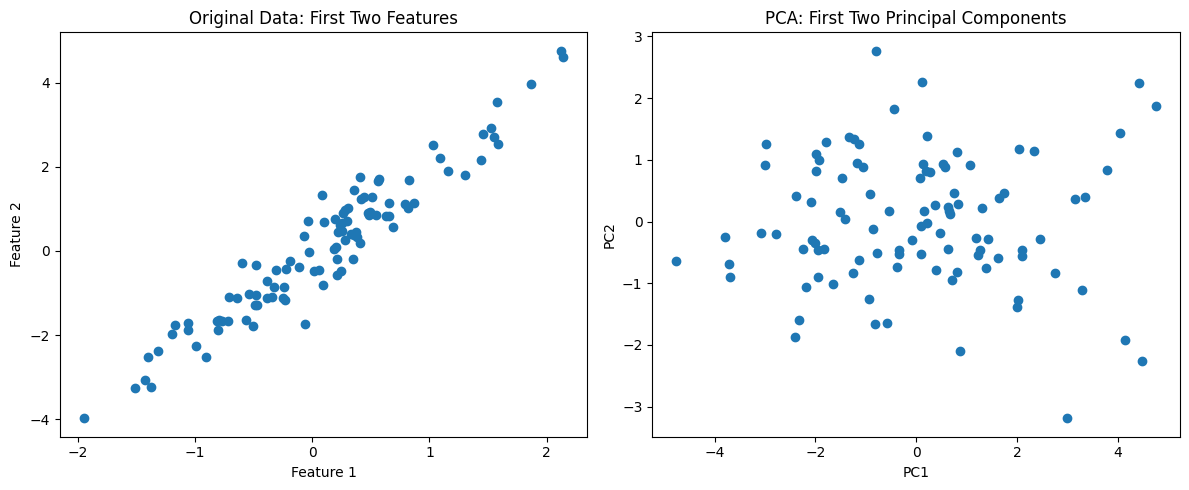

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X[:, 0], X[:, 1])
ax[0].set_title("Original Data: First Two Features")
ax[0].set_xlabel("Feature 1")
ax[0].set_ylabel("Feature 2")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1])
ax[1].set_title("PCA: First Two Principal Components")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()



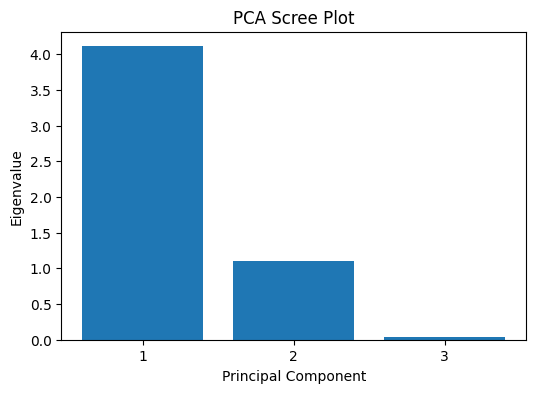

In [59]:
# 10. Scree plot
plt.figure(figsize=(6, 4))
plt.bar(
    range(1, len(eigenvalues) + 1),
    eigenvalues
)
plt.xticks(range(1, len(eigenvalues) + 1))
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("PCA Scree Plot")
plt.show()

#<font color='red'>LDA</font>

# 1. Generate a labeled dataset with 3 classes

In [60]:
np.random.seed(42)
n = 50
class0 = np.random.randn(n, 3) + [0, 0, 0]
class1 = np.random.randn(n, 3) + [3, 3, 1]
class2 = np.random.randn(n, 3) + [0, 4, 3]

X = np.vstack([class0, class1, class2])

y = np.array(
    [0] * n + [1] * n + [2] * n
)

print("Original shape:", X.shape)
print("Classes:", np.unique(y))

Original shape: (150, 3)
Classes: [0 1 2]


# 2. Calculate overall mean

In [61]:
overall_mean = np.mean(X, axis=0)

# 3. Initialize scatter matrices

In [62]:
n_features = X.shape[1]

Sw = np.zeros((n_features, n_features))
Sb = np.zeros((n_features, n_features))

# 4. Calculate within-class and between-class scatter

In [63]:
for c in np.unique(y):
    Xc = X[y == c]

    class_mean = np.mean(Xc, axis=0)
    class_size = len(Xc)

    # Within-class scatter
    Xc_centered = Xc - class_mean
    Sw += Xc_centered.T @ Xc_centered

    # Between-class scatter
    mean_diff = (class_mean - overall_mean).reshape(-1, 1)

    Sb += class_size * (mean_diff @ mean_diff.T)

print("\nWithin-class scatter Sw:\n", Sw)
print("\nBetween-class scatter Sb:\n", Sb)


Within-class scatter Sw:
 [[113.46782864   6.43702013 -11.75529901]
 [  6.43702013 141.39671526 -10.22792024]
 [-11.75529901 -10.22792024 158.72445562]]

Between-class scatter Sb:
 [[349.29978673  94.69958089 -24.10469587]
 [ 94.69958089 443.44909402 323.50477607]
 [-24.10469587 323.50477607 262.39313676]]


# 5. Solve generalized eigenvalue problem
# Sb v = lambda Sw v
# Small regularization improves numerical stability

In [64]:
regularization = 1e-6
Sw_regularized = Sw + regularization * np.eye(n_features)

matrix = np.linalg.solve(Sw_regularized, Sb)

eigenvalues, eigenvectors = np.linalg.eig(matrix)

# Convert to real values to remove numerical round-off noise

In [65]:
eigenvalues = np.real(eigenvalues)
eigenvectors = np.real(eigenvectors)

# 6. Sort by descending eigenvalue

In [66]:
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("\nEigenvalues:\n", eigenvalues)


Eigenvalues:
 [5.15994181e+00 2.95966925e+00 6.54773139e-16]


# 7. Select up to C - 1 components

In [67]:
num_classes = len(np.unique(y))
k = min(2, num_classes - 1)
components = eigenvectors[:, :k]

# 8. Project data

In [68]:
X_lda = (X - overall_mean) @ components

print("\nReduced shape:", X_lda.shape)


Reduced shape: (150, 2)


# 9. Visualize LDA projection

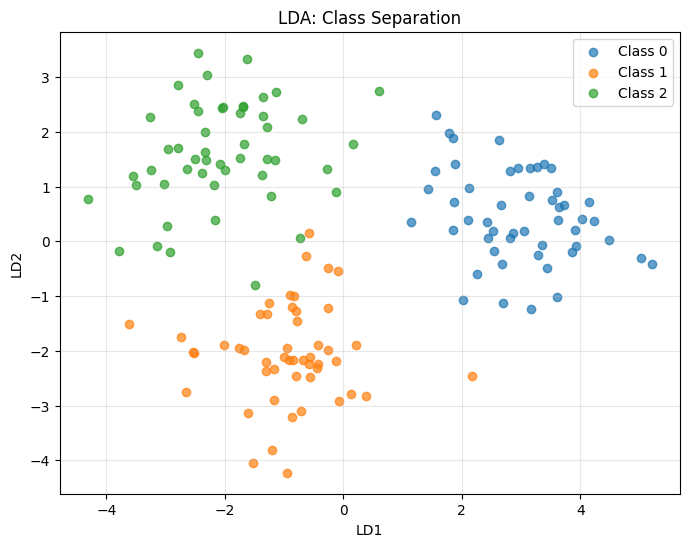

In [69]:
plt.figure(figsize=(8, 6))

for c in np.unique(y):
    plt.scatter(
        X_lda[y == c, 0],
        X_lda[y == c, 1],
        label=f"Class {c}",
        alpha=0.7
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA: Class Separation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
